In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
data = pd.read_csv('bank-full.csv', sep=';')

In [7]:
data.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [8]:
data.tail()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [9]:
data.shape

(45211, 17)

In [10]:
data.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [12]:
data.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [13]:
data['y'].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

In [14]:
data['y'].value_counts(normalize=True)*100

y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64

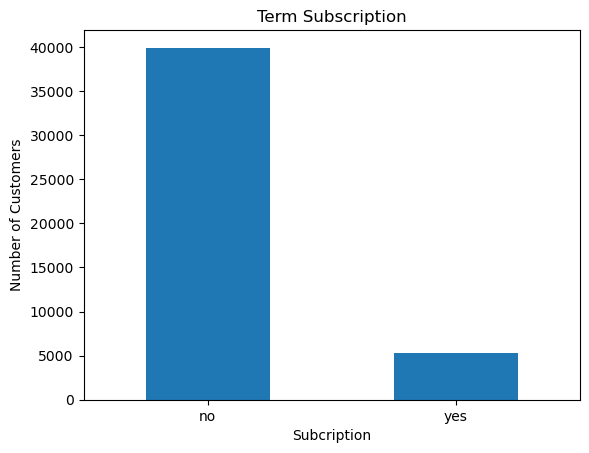

In [16]:
counts = data['y'].value_counts().reindex(['no','yes'])
counts.plot (kind='bar')
plt.title('Term Subscription')
plt.xlabel('Subcription')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

In [17]:
age_min=data['age'].min()
age_max=data['age'].max()
print(age_min, age_max)

18 95


In [18]:
range=age_max - age_min
print(range)

77


In [20]:
variance = data['age'].var()
print(variance)

112.75810728286069


In [21]:
standard_dev=data['age'].std()
print(standard_dev)

10.618762040975431


In [23]:
p10=data['age'].quantile(0.10)
p25=data['age'].quantile(0.25)
p50=data['age'].quantile(0.50)
p75=data['age'].quantile(0.75)
print(p10, p25, p50, p75)

29.0 33.0 39.0 48.0


In [24]:
Q3=data['age'].quantile(0.75)
Q1=data['age'].quantile(0.25)
IQR = Q3-Q1
print(IQR)

15.0


In [26]:
lower_bound= Q1 - 1.5 * IQR
upper_bound= Q3 + 1.5 * IQR
outliers=data[(data['age']<lower_bound) | (data['age']> upper_bound)]
print('lower_bound', lower_bound)
print('upper_bound', lower_bound)
print('number of outliers', len(outliers))

lower_bound 10.5
upper_bound 10.5
number of outliers 487


In [27]:
outliers['age']

29158    83
29261    75
29263    75
29322    83
29865    75
         ..
45163    71
45191    75
45204    73
45207    71
45208    72
Name: age, Length: 487, dtype: int64

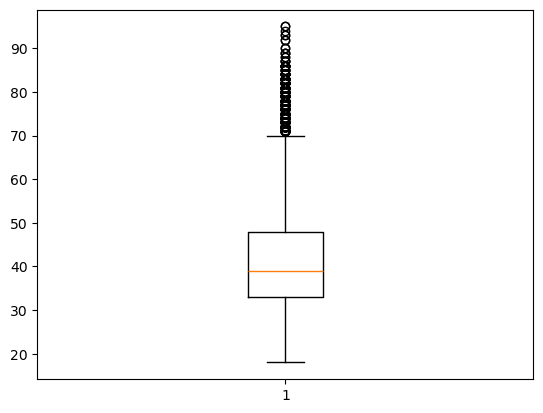

In [28]:
plt.boxplot(data['age'])
plt.show()

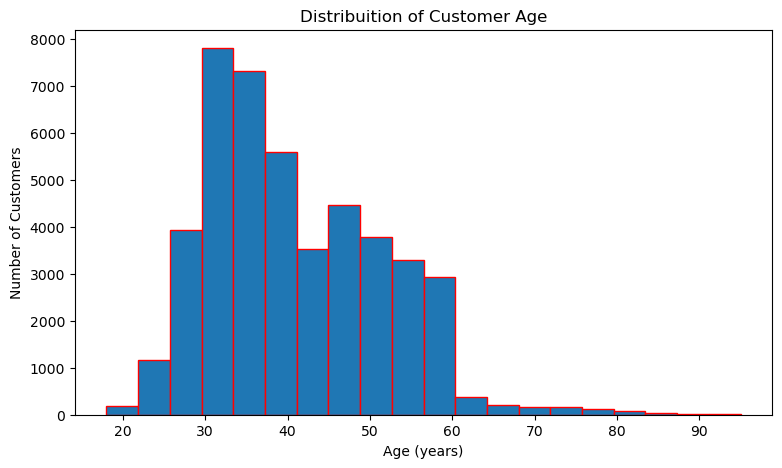

In [31]:
plt.figure(figsize=(9,5))
plt.hist(data['age'], bins=20, edgecolor='red')
plt.title("Distribuition of Customer Age")
plt.xlabel("Age (years)")
plt.ylabel('Number of Customers')
plt.show()

# Binominal

n = Number of Clients
p = probability to subscribe


In [33]:
# Count the total number of customers
n_customers = len(data)

# Count the number of customers who subscribed
n_success = (data['y'] == 'yes').sum()

# Calculate the subscription probability
p = n_success / n_customers

print('Total of customers:', n_customers)
print('Successful Subscriptions:', n_success)
print('Estimated probability of subscriptions:', p)
print('Subscriptions percentage:', p*100)

Total of customers: 45211
Successful Subscriptions: 5289
Estimated probability of subscriptions: 0.11698480458295547
Subscriptions percentage: 11.698480458295547


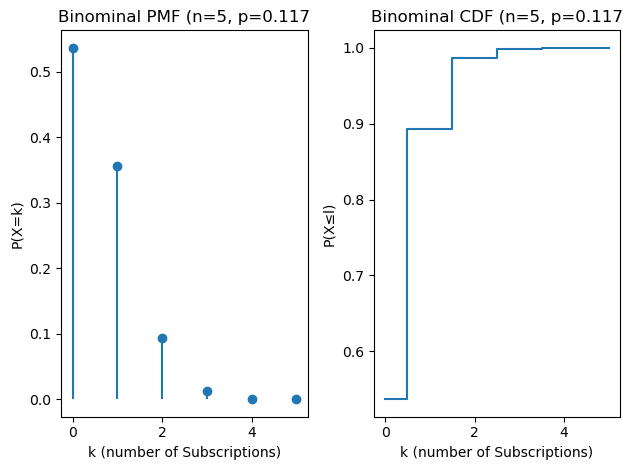

In [36]:
from scipy.stats import binom
# n = number of customers
# p = estimated probability of subscriptions
n, p = 5, 0.11698480458295547

#Possible number of successful subcriptions
x = np.arange(0, n +1)

# PMF and CDF
pmf = binom.pmf(x, n, p)
cdf = binom.cdf(x, n, p)

# PMF PLOT

plt.subplot(1, 2, 1)
plt.stem (x, pmf, basefmt=" ")
plt.title('Binominal PMF (n=5, p=0.117')
plt.xlabel('k (number of Subscriptions)')
plt.ylabel('P(X=k)')

# CDF PLOT
plt.subplot(1,2,2)
plt.step(x, cdf, where="mid")
plt.title('Binominal CDF (n=5, p=0.117')
plt.xlabel('k (number of Subscriptions)')
plt.ylabel('P(X≤l)')

plt.tight_layout()
plt.show()
